# Credit Risk Classification — draft 3

This notebook follows the requested classroom workflow and makes the leakage rule explicit. The source dataset is understood first; then the development/test split is created before any operation that learns distributional information. Pre-split checks are limited to immutable schema, target, and data-integrity validation; all distribution-based decisions in steps 2–6 use training/development data only.

**Business question:** which applications should receive enhanced human review when only 20% can be reviewed? The positive class is `bad/default-risk`: `1` means the historical application is labelled bad credit risk.

## 0. Understand and prove the data

Before modelling, state what one row means, what the target means, which class is positive, and which variables are numeric or categorical. Then prove the assumptions with assertions. This is not yet training: no scaler, encoder, or model is fitted here.

The full-data inspection is descriptive only. We do not use full-data means, category frequencies, or outlier thresholds to train the model. The South German Credit file is a historical credit-risk dataset from the 1970s, with 1,000 records and a `bad/good` label; it is not a directly observed modern 12-month default dataset.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'data_contract.py').exists() and (candidate / 'data' / 'raw').exists():
            return candidate
    raise FileNotFoundError('Could not locate the assignment project root')

ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_contract import load_raw_data, make_xy, contract_summary, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS

RAW_PATH = ROOT / 'data' / 'raw' / 'SouthGermanCredit.asc'
frame = load_raw_data(RAW_PATH)
X_raw, y = make_xy(frame)

assert frame.shape == (1000, 21)
assert frame['kredit'].isin([0, 1]).all()
assert frame.isna().sum().sum() == 0
assert frame.duplicated().sum() == 0
assert set(NUMERIC_COLUMNS) == {'laufzeit', 'hoehe', 'alter'}
assert len(CATEGORICAL_COLUMNS) == 17

print('Proven: 1,000 rows, 20 predictors, no nulls, no duplicate rows, binary target, and the declared column contract.')
print('Positive class: bad/default-risk = raw kredit == 0 -> model target 1')
display(frame.head())

Proven: 1,000 rows, 20 predictors, no nulls, no duplicate rows, binary target, and the declared column contract.
Positive class: bad/default-risk = raw kredit == 0 -> model target 1


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


In [2]:
feature_dictionary = {
    'laufkont': 'existing checking-account status', 'laufzeit': 'loan duration in months',
    'moral': 'credit history', 'verw': 'loan purpose', 'hoehe': 'credit amount',
    'sparkont': 'savings account or bonds', 'beszeit': 'employment duration',
    'rate': 'installment rate as percentage of disposable income', 'famges': 'personal status and sex code',
    'buerge': 'other debtors or guarantors', 'wohnzeit': 'years at present residence',
    'verm': 'property status', 'alter': 'age in years', 'weitkred': 'other installment plans',
    'wohn': 'housing status', 'bishkred': 'number of existing credits at this bank',
    'beruf': 'job category', 'pers': 'number of people financially liable for',
    'telef': 'telephone status', 'gastarb': 'foreign-worker code', 'kredit': 'historical credit-risk target'
}
column_table = pd.DataFrame({
    'column': frame.columns,
    'role': ['target' if c == 'kredit' else 'predictor' for c in frame.columns],
    'type_used_by_model': ['target' if c == 'kredit' else ('numeric' if c in NUMERIC_COLUMNS else 'categorical') for c in frame.columns],
    'meaning': [feature_dictionary[c] for c in frame.columns]
})
display(column_table)
display(pd.DataFrame({'raw_label': frame['kredit'].value_counts().sort_index(), 'meaning': ['bad/default-risk', 'good/performing']}))

,column,role,type_used_by_model,meaning
0,laufkont,predictor,categorical,existing checking-account status
1,laufzeit,predictor,numeric,loan duration in months
2,moral,predictor,categorical,credit history
3,verw,predictor,categorical,loan purpose
4,hoehe,predictor,numeric,credit amount
5,sparkont,predictor,categorical,savings account or bonds
6,beszeit,predictor,categorical,employment duration
7,rate,predictor,categorical,installment rate as percentage of disposable i...
8,famges,predictor,categorical,personal status and sex code
9,buerge,predictor,categorical,other debtors or guarantors


,raw_label,meaning
kredit,,
0,300,bad/default-risk
1,700,good/performing


## 1. Clean the data: duplicates and nulls

We check duplicates and nulls because duplicated rows can give one case artificial weight in statistics such as the mean, mode, variance, and standard deviation. Nulls require an explicit strategy. These are pre-split integrity checks; they do not estimate a model parameter.

Here the source contract proves that neither issue exists. If this were a messy new dataset, raw duplicate records would be resolved as a data-integrity decision; learned imputation values would be fitted on training data only inside the pipeline.

In [3]:
cleaning_report = pd.DataFrame({
    'check': ['missing cells', 'duplicate rows', 'constant predictors', 'unexpected target values'],
    'count': [
        int(frame.isna().sum().sum()),
        int(frame.duplicated().sum()),
        int(sum(frame[c].nunique() <= 1 for c in X_raw.columns)),
        int((~frame['kredit'].isin([0, 1])).sum()),
    ]
})
display(cleaning_report)
assert cleaning_report['count'].tolist() == [0, 0, 0, 0]
print('No cleaning decision is learned from the test distribution; no rows require removal or imputation.')
X_clean, y_clean = X_raw.copy(), y.copy()

,check,count
0,missing cells,0
1,duplicate rows,0
2,constant predictors,0
3,unexpected target values,0


No cleaning decision is learned from the test distribution; no rows require removal or imputation.


## Leakage checkpoint: split before learned steps

Your checklist labels the split as step 4, but the implementation must perform it before calculating training statistics for outliers, encoding, visual diagnostics used for decisions, or scaling. Otherwise the model can learn from the test set: **data leakage**.

We therefore create the split here and then execute steps 2–6 on `X_train`/`y_train` only. The test set stays untouched until prediction and final evaluation.

In [4]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 77
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.20, stratify=y_clean, random_state=RANDOM_STATE
)
split_report = pd.DataFrame({
    'split': ['training/development', 'test/frozen'],
    'rows': [len(y_train), len(y_test)],
    'bad/default-risk': [int(y_train.sum()), int(y_test.sum())],
    'bad-risk rate': [y_train.mean(), y_test.mean()]
})
display(split_report)
print('The 20% test set is now frozen; it is not used to learn preprocessing or select the policy.')

,split,rows,bad/default-risk,bad-risk rate
0,training/development,800,240,0.3
1,test/frozen,200,60,0.3


The 20% test set is now frozen; it is not used to learn preprocessing or select the policy.


## 2. Outliers: detect first, remove only actual errors

An IQR flag means ‘unusual relative to the training distribution’; it does not mean ‘wrong’. We calculate IQR bounds using training data only, inspect bounded examples, and do not delete them automatically.

In the credit case, a very large loan may be a real and important risk signal. Removing it could make the model less realistic. A deletion would require a domain rule such as an impossible negative amount—not merely a large value.

In [5]:
def iqr_report(training_frame, columns):
    rows = []
    for column in columns:
        q1, q3 = training_frame[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flagged = ((training_frame[column] < lower) | (training_frame[column] > upper))
        rows.append({'column': column, 'lower_bound': lower, 'upper_bound': upper, 'flagged_count': int(flagged.sum()), 'action': 'inspect; do not delete automatically'})
    return pd.DataFrame(rows)

outlier_report = iqr_report(X_train, NUMERIC_COLUMNS)
display(outlier_report)

flagged_examples = []
for column in NUMERIC_COLUMNS:
    q1, q3 = X_train[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (X_train[column] < q1 - 1.5 * iqr) | (X_train[column] > q3 + 1.5 * iqr)
    for row_id, value in X_train.loc[mask, column].head(5).items():
        flagged_examples.append({'row_id': row_id, 'column': column, 'value': value, 'review_decision': 'valid-looking extreme; retained'})
display(pd.DataFrame(flagged_examples))

def domain_error_counts(dataset):
    return {
        'duration <= 0': int((dataset['laufzeit'] <= 0).sum()),
        'amount <= 0': int((dataset['hoehe'] <= 0).sum()),
        'age <= 0': int((dataset['alter'] <= 0).sum()),
    }
domain_errors = pd.DataFrame([
    {'split': name, **domain_error_counts(dataset)}
    for name, dataset in [('full raw data', X_clean), ('training', X_train), ('test', X_test)]
])
display(domain_errors)
assert domain_errors.iloc[:, 1:].to_numpy().sum() == 0
print('Decision: retain valid extreme values; no outliers are removed.')

,column,lower_bound,upper_bound,flagged_count,action
0,laufzeit,-6.00,42.00,56,inspect; do not delete automatically
1,hoehe,-2506.75,7779.25,63,inspect; do not delete automatically
2,alter,4.50,64.50,14,inspect; do not delete automatically


,row_id,column,value,review_decision
0,695,laufzeit,60,valid-looking extreme; retained
1,541,laufzeit,48,valid-looking extreme; retained
2,405,laufzeit,48,valid-looking extreme; retained
3,940,laufzeit,48,valid-looking extreme; retained
4,218,laufzeit,47,valid-looking extreme; retained
5,572,hoehe,7966,valid-looking extreme; retained
6,728,hoehe,11054,valid-looking extreme; retained
7,695,hoehe,15653,valid-looking extreme; retained
8,940,hoehe,10127,valid-looking extreme; retained
9,218,hoehe,10722,valid-looking extreme; retained


,split,duration <= 0,amount <= 0,age <= 0
0,full raw data,0,0,0
1,training,0,0,0
2,test,0,0,0


Decision: retain valid extreme values; no outliers are removed.


## 3. Contradictions, inefficiencies, and categorical encoding

We check impossible values and low-information columns first. The categorical codes are labels, not automatically meaningful numbers: nominal variables use one-hot encoding; ordered variables may use ordinal encoding only when the order is justified.

The working project uses one-hot encoding for the categorical predictors and keeps the transformation inside each model pipeline. Thus the encoder learns categories from training folds and handles an unseen category safely. Some source variables have an order (for example employment duration, installment rate, residence duration, and number of credits); an ordinal alternative would need an explicit codebook mapping and must be compared on development data only.

In [6]:
contradiction_report = pd.DataFrame({
    'check': ['duration <= 0', 'amount <= 0', 'age <= 0', 'zero-information predictors'],
    'training_violations': [
        int((X_train['laufzeit'] <= 0).sum()),
        int((X_train['hoehe'] <= 0).sum()),
        int((X_train['alter'] <= 0).sum()),
        int(sum(X_train[c].nunique() <= 1 for c in X_train.columns)),
    ]
})
display(contradiction_report)

allowed_codes = {
    'laufkont': set(range(1, 5)), 'moral': set(range(0, 5)), 'verw': set(range(0, 11)),
    'sparkont': set(range(1, 6)), 'beszeit': set(range(1, 6)), 'rate': set(range(1, 5)),
    'famges': set(range(1, 5)), 'buerge': set(range(1, 4)), 'wohnzeit': set(range(1, 5)),
    'verm': set(range(1, 5)), 'weitkred': set(range(1, 4)), 'wohn': set(range(1, 4)),
    'bishkred': set(range(1, 5)), 'beruf': set(range(1, 5)), 'pers': set(range(1, 3)),
    'telef': set(range(1, 3)), 'gastarb': set(range(1, 3))
}
code_report = pd.DataFrame([
    {'column': column, 'invalid_codes': sorted(set(frame[column].unique()) - allowed)}
    for column, allowed in allowed_codes.items()
])
display(code_report)
assert all(len(values) == 0 for values in code_report['invalid_codes'])
print('Numeric predictors:', NUMERIC_COLUMNS)
print('Categorical predictors:', CATEGORICAL_COLUMNS)

,check,training_violations
0,duration <= 0,0
1,amount <= 0,0
2,age <= 0,0
3,zero-information predictors,0


,column,invalid_codes
0,laufkont,[]
1,moral,[]
2,verw,[]
3,sparkont,[]
4,beszeit,[]
5,rate,[]
6,famges,[]
7,buerge,[]
8,wohnzeit,[]
9,verm,[]


Numeric predictors: ['laufzeit', 'hoehe', 'alter']
Categorical predictors: ['laufkont', 'moral', 'verw', 'sparkont', 'beszeit', 'rate', 'famges', 'buerge', 'wohnzeit', 'verm', 'weitkred', 'wohn', 'bishkred', 'beruf', 'pers', 'telef', 'gastarb']


## 4. Train/test split — the formal rule

The split was created at the leakage checkpoint above because later operations must use training data only. An 80/20 split is the assignment convention; 70/30 can be reasonable when the dataset is larger or when a larger final test estimate is needed. With only 1,000 rows, stratification is important.

Bad sequence: fit a scaler on all rows, then split. Correct sequence: fit the scaler on training rows and only transform test rows.

## 5. Visualise the starting training data

These diagnostic plots use training data only. Visualisation can reveal skew, unusual values, class imbalance, and coding issues without allowing the test distribution to influence preprocessing or model selection.

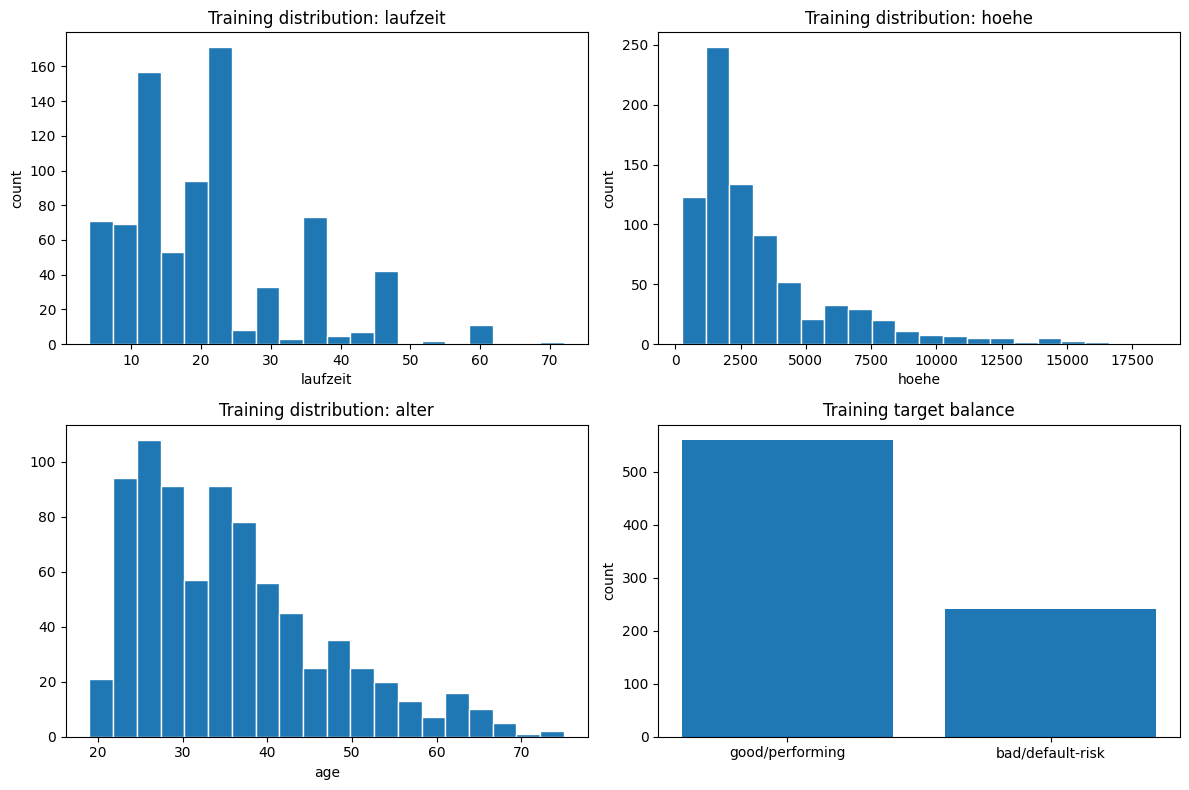

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes[0], ['laufzeit', 'hoehe']):
    ax.hist(X_train[column], bins=20, edgecolor='white')
    ax.set_title(f'Training distribution: {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('count')
axes[1, 0].hist(X_train['alter'], bins=20, edgecolor='white')
axes[1, 0].set_title('Training distribution: alter')
axes[1, 0].set_xlabel('age')
axes[1, 1].bar(['good/performing', 'bad/default-risk'], [(y_train == 0).sum(), (y_train == 1).sum()])
axes[1, 1].set_title('Training target balance')
axes[1, 1].set_ylabel('count')
plt.tight_layout()
plt.show()

## 5b. Visualise categorical predictors

`fit_transform()` learns the training medians, category levels, and numeric scaling parameters. `transform()` applies those already-learned parameters to the test set. The test set supplies no statistics.

These category plots are still part of step 5. They help us see rare or absent codes before encoding; they do not justify deleting a category using test-set information.

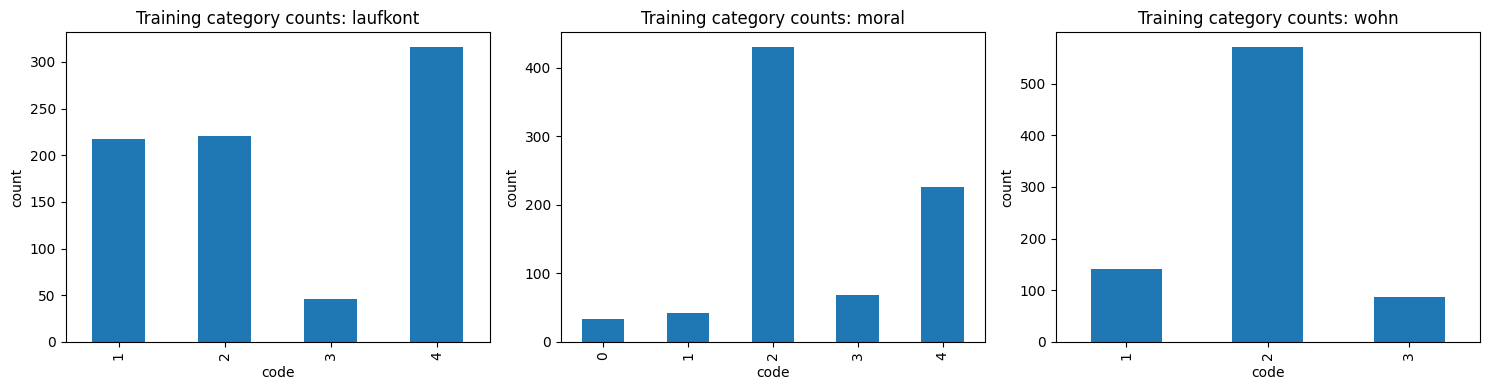

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ['laufkont', 'moral', 'wohn']):
    X_train[column].value_counts().sort_index().plot(kind='bar', ax=ax)
    ax.set_title(f'Training category counts: {column}')
    ax.set_xlabel('code')
    ax.set_ylabel('count')
plt.tight_layout()
plt.show()

The numeric plots show scale and skew; the categorical plots show whether some codes are rare or unexpectedly absent. They inform inspection, but they do not justify deleting a category or feature using test-set information.

## 6. Scale and normalise — fitted on training only

`fit_transform()` learns the training medians, category levels, and numeric scaling parameters. `transform()` applies those already-learned parameters to the test set. The test set supplies no statistics.

For example, StandardScaler changes a numeric variable to a comparable scale; it does not make an intrinsically categorical code meaningful.

In [9]:
from src.preprocessing import make_preprocessor

preprocessor_demo = make_preprocessor()
X_train_transformed = preprocessor_demo.fit_transform(X_train)
X_test_transformed = preprocessor_demo.transform(X_test)
print('Transformed training shape:', X_train_transformed.shape)
print('Transformed test shape:', X_test_transformed.shape)
print('Correct: fit_transform(training), then transform(test).')

Transformed training shape: (800, 71)
Transformed test shape: (200, 71)
Correct: fit_transform(training), then transform(test).


## 7. Fit and train each model

`fit()` is the training action: we feed the model the training predictors and labels, and it learns a decision function. Each candidate contains its own preprocessing pipeline, so the same leakage-safe rules are applied during cross-validation.

In [10]:
from src.models import make_candidate_models

models = make_candidate_models(random_state=RANDOM_STATE)
fitted_models = {}
for name, model in models.items():
    fitted_models[name] = model.fit(X_train, y_train)
print('Fitted models:', list(fitted_models))

Fitted models: ['majority_baseline', 'logistic_regression', 'decision_tree', 'random_forest']


## 8. Predict on the test data

`predict()` returns a class after applying the model's default threshold. `predict_proba()` returns a risk score, which is more useful here because the business policy ranks applicants and selects the highest-risk 20%. All candidate models are trained above; the frozen test is scored only by the model already selected on development data.

In [11]:
policy_manifest = json.loads((ROOT / 'artifacts' / 'manifests' / 'wave-4-policy.json').read_text(encoding='utf-8'))
selected_model_name = policy_manifest['selected_model']
selected_fitted_model = fitted_models[selected_model_name]
test_predictions = {selected_model_name: selected_fitted_model.predict(X_test)}
test_risk_scores = {selected_model_name: selected_fitted_model.predict_proba(X_test)[:, 1]}

prediction_preview = pd.DataFrame({
    'actual_bad_risk': y_test.to_numpy(),
    'selected_model_bad_risk_score': test_risk_scores[selected_model_name],
    'selected_model_predict_at_0.50': test_predictions[selected_model_name],
}).head(10)
display(prediction_preview)

,actual_bad_risk,selected_model_bad_risk_score,selected_model_predict_at_0.50
0,0,0.308159,0
1,0,0.328312,0
2,1,0.161974,0
3,0,0.172685,0
4,1,0.701218,1
5,0,0.014984,0
6,0,0.062653,0
7,0,0.078632,0
8,0,0.052023,0
9,0,0.328820,0


## 9. Evaluate each model without choosing on the test set

We use the stored development out-of-fold results to compare candidates and choose the operating model. The frozen test is then used once for confirmation. Accuracy, precision, recall, and F1 are reported together; the business objective also includes review capacity and expected screening value.

In [12]:
import hashlib
from src.evaluation import binary_metrics
from src.threshold_policy import metrics_at_capacity, BUSINESS_ASSUMPTIONS

oof = pd.read_csv(ROOT / 'artifacts' / 'tables' / 'wave-4-oof-threshold-table-all-models.csv')
oof_capacity = oof[oof['policy'].eq('recommended_capacity_constrained')].sort_values('net_screening_value', ascending=False)
display(oof_capacity[['model', 'accuracy', 'precision', 'recall', 'f1', 'monthly_reviews', 'net_screening_value']])

policy_manifest = json.loads((ROOT / 'artifacts' / 'manifests' / 'wave-4-policy.json').read_text(encoding='utf-8'))
run_manifest = json.loads((ROOT / 'artifacts' / 'manifests' / 'waves-0-3-run.json').read_text(encoding='utf-8'))
raw_hash = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
assert run_manifest['raw_source']['sha256'] == raw_hash
assert run_manifest['random_state'] == RANDOM_STATE
selected_model_name = policy_manifest['selected_model']
assert selected_model_name == oof_capacity.iloc[0]['model']
print('Selected by development OOF business value:', selected_model_name)
print('Business assumptions:', BUSINESS_ASSUMPTIONS)

,model,accuracy,precision,recall,f1,monthly_reviews,net_screening_value
11,logistic_regression,0.7525,0.63125,0.420833,0.505,1600.0,2635600.0
23,random_forest,0.7425,0.60625,0.404167,0.485,1600.0,2525200.0
17,decision_tree,0.7050,0.51250,0.341667,0.410,1600.0,2111200.0
5,majority_baseline,0.6325,0.33125,0.220833,0.265,1600.0,1310800.0


Selected by development OOF business value: logistic_regression
Business assumptions: {'monthly_applications': 8000, 'max_monthly_reviews': 1600, 'review_cost': 35.0, 'lgd': 6000.0, 'review_effectiveness': 0.45, 'performing_contribution': 1200.0, 'abandonment_rate': 0.05}


In [13]:
selected_score = test_risk_scores[selected_model_name]
selected_default = binary_metrics(y_test, selected_score, threshold=0.50)
selected_top20 = metrics_at_capacity(
    y_test, selected_score,
    BUSINESS_ASSUMPTIONS['max_monthly_reviews'] / BUSINESS_ASSUMPTIONS['monthly_applications']
)
selected_metrics = pd.DataFrame([
    {'policy': 'threshold = 0.50', **{key: selected_default[key] for key in ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision', 'brier']}},
    {'policy': 'ranked top 20%', **{key: selected_top20[key] for key in ['accuracy', 'precision', 'recall', 'f1']}, 'balanced_accuracy': None, 'roc_auc': None, 'average_precision': None, 'brier': None}
])
display(selected_metrics)
display(pd.DataFrame([selected_top20])[['tn', 'fp', 'fn', 'tp', 'monthly_reviews', 'net_screening_value', 'cost_per_expected_default_prevented']])
print('TP = bad-risk cases sent to review; FN = bad-risk cases missed by the queue.')

,policy,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier
0,threshold = 0.50,0.74,0.652381,0.590909,0.433333,0.5,0.741786,0.589778,0.17936
1,ranked top 20%,0.75,NaN,0.625000,0.416667,0.5,NaN,NaN,NaN


,tn,fp,fn,tp,monthly_reviews,net_screening_value,cost_per_expected_default_prevented
0,125,15,35,25,1600.0,2608000.0,124.444444


TP = bad-risk cases sent to review; FN = bad-risk cases missed by the queue.


## 10. Iterate

Iteration means changing one justified element, retraining on development data, and comparing the new result against the same frozen policy. We do not repeatedly tune against the test set.

Good next iterations are calibration, temporal validation with newer data, better measurement of review effectiveness, subgroup error analysis, and testing whether a domain-supported ordinal encoding improves performance. The current notebook completes the baseline iteration and records the next experiments; it does not pretend that one historical split proves production performance.

In [14]:
iteration_plan = pd.DataFrame({
    'iteration': ['baseline', 'calibration', 'temporal validation', 'governance'],
    'change': [
        'current leakage-safe pipelines and top-20% review policy',
        'check whether risk scores correspond to observed label frequencies',
        'test on a later time period if dates become available',
        'compare subgroup precision, recall, and false-positive rates'
    ],
    'test-set rule': ['frozen confirmation', 'reuse same frozen test once', 'use a new temporal holdout', 'audit only; never tune silently']
})
display(iteration_plan)

,iteration,change,test-set rule
0,baseline,current leakage-safe pipelines and top-20% rev...,frozen confirmation
1,calibration,check whether risk scores correspond to observ...,reuse same frozen test once
2,temporal validation,test on a later time period if dates become av...,use a new temporal holdout
3,governance,"compare subgroup precision, recall, and false-...",audit only; never tune silently


## Conclusion

The model produces a score for the historical bad/good label; `predict_proba()` is not automatically a calibrated future-default probability. It creates a ranked review queue; it does not prove causality and it does not automatically approve or reject. The validated baseline selects Logistic Regression on development out-of-fold business value, then confirms the top-20% policy once on the frozen test.

The essential learning rule is: **understand first, split before learned transformations, fit only on training data, predict on unseen test data, evaluate, then iterate without contaminating the test set.**